# ROPE-TIEGCM V1 demo
Reduced-Order Probabilistic Emulator of TIE-GCM thermospheric density, driven by **F10.7, its 41-day average and ap**.

* Initial condition from the IC table, drivers from CelesTrak (or the TIE-GCM drivers)
* 15-model ensemble (LSTM, GRU, Transformer) fused by a meta-model, decoded by a convolutional autoencoder
* `density_std`: model uncertainty, **calibrated** (σ / 0.747, see README)

Run from the repository root.

In [1]:
import os, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
from rope import ROPE
from interpolator import DensityInterpolator

rope = ROPE(device="cuda")                    # CelesTrak drivers; ROPE(drivers="tiegcm") for 1996-2009


ROPE ready  [drivers=sw_celestrack_1957_ap.csv.gz  device=cuda]



## 1. A 5-day forecast through the May 2024 storm

In [2]:
t0 = time.time()
out = rope.run("2024-05-09 00:00", horizon=120)          # uncertainty=True by default
print(f"{time.time() - t0:.1f} s")
print("mean_density", out["mean_density"].shape, "| density_std", out["density_std"].shape, "(hour, LST, lat, alt)")
out["window_df"].head()

10.0 s
mean_density (120, 72, 36, 45) | density_std (120, 72, 36, 45) (hour, LST, lat, alt)


,datetime,f10,f10_41day_avg,ap
0,2024-05-09 00:00:00,233.200000,163.251778,3.000000
1,2024-05-09 01:00:00,232.791667,163.319508,3.666667
2,2024-05-09 02:00:00,232.383333,163.387995,4.333333
3,2024-05-09 03:00:00,231.975000,163.457241,5.000000
4,2024-05-09 04:00:00,231.566667,163.527244,4.333333


## 2. Global-mean density at 400 km, its uncertainty, and the drivers

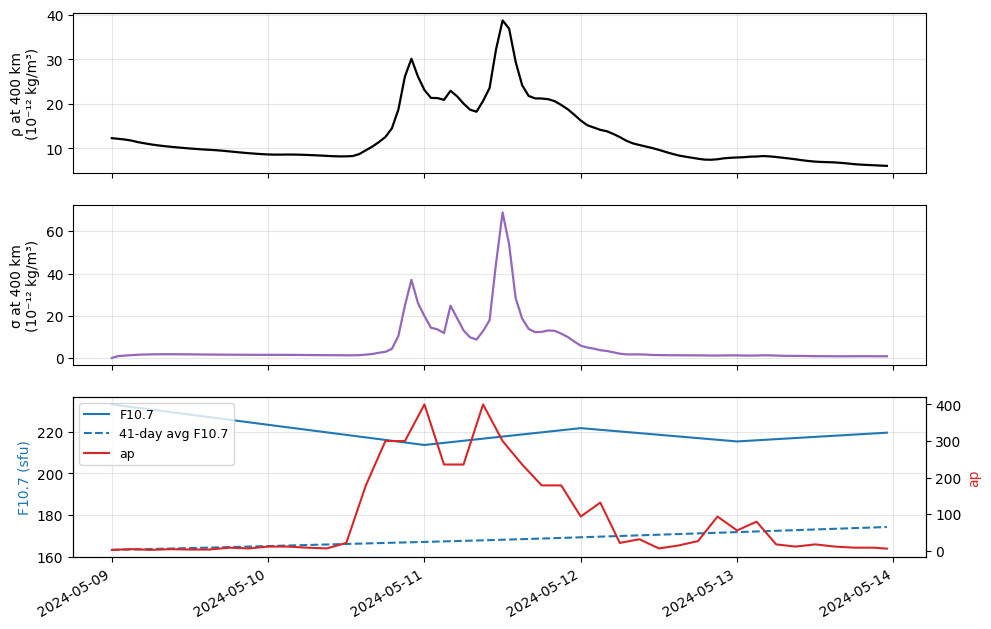

In [3]:
alt = np.linspace(100, 980, 45); lat = np.linspace(-87.5, 87.5, 36)
k = int(np.argmin(abs(alt - 400)))
w = np.cos(np.deg2rad(lat))[None, :]
gm = lambda a: (a[:, :, :, k] * w).sum((1, 2)) / (w.sum() * a.shape[1])
t, rho, sig = out["window_df"].datetime, gm(out["mean_density"]), gm(out["density_std"])

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(t, rho * 1e12, "k", lw=1.6)
ax[0].set_ylabel("ρ at 400 km\n(10⁻¹² kg/m³)")
ax[1].plot(t, sig * 1e12, "tab:purple", lw=1.6)
ax[1].set_ylabel("σ at 400 km\n(10⁻¹² kg/m³)")
ax[2].plot(t, out["window_df"].f10, "tab:blue", label="F10.7")
ax[2].plot(t, out["window_df"].f10_41day_avg, "tab:blue", ls="--", label="41-day avg F10.7")
ax[2].set_ylabel("F10.7 (sfu)", color="tab:blue")
a2 = ax[2].twinx(); a2.plot(t, out["window_df"].ap, "tab:red", label="ap"); a2.set_ylabel("ap", color="tab:red")
h1, l1 = ax[2].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
ax[2].legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
for a in ax: a.grid(alpha=0.3)
fig.autofmt_xdate(); plt.show()

## 3. Density at a point, e.g. along an orbit

In [4]:
q = DensityInterpolator(out)
q.query("2024-05-11 06:30", lst=14.0, lat=30.0, alt_km=450.0, time_mode="interp_time")

{'datetime': Timestamp('2024-05-11 06:30:00'),
 'density': 1.0678303726916391e-11,
 't_index_left': 54,
 't_index_right': 55,
 'datetime_left': Timestamp('2024-05-11 06:00:00'),
 'datetime_right': Timestamp('2024-05-11 07:00:00'),
 'time_weight_right': 0.5,
 'time_mode': 'interp_time',
 'alt_regime': 'grid_interpolation',
 'sigma': 5.111131731895853e-12}

## 4. Options
* `rope.run(..., uncertainty=False)`: fast deterministic run
* `rope.run(..., warmup_hours=48)`: start 48 h earlier so the IC-table error has faded by the start
* `ROPE(drivers="tiegcm")`: the TIE-GCM training drivers (1996-2009); `ROPE(driver_csv=...)`: your own hourly `datetime, f10, ap`

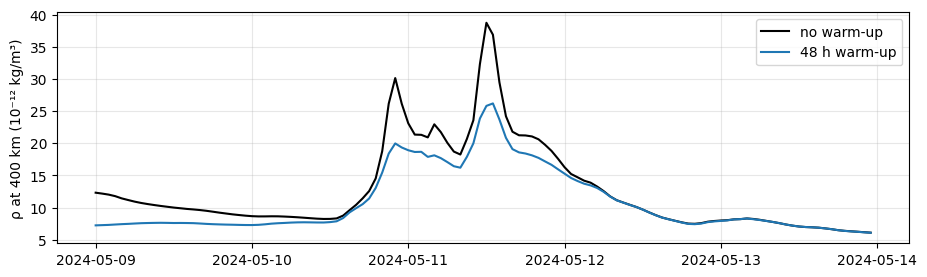

In [5]:
wu = rope.run("2024-05-09 00:00", horizon=120, warmup_hours=48, uncertainty=False)
plt.figure(figsize=(11, 3))
plt.plot(t, rho * 1e12, "k", label="no warm-up"); plt.plot(t, gm(wu["mean_density"]) * 1e12, "tab:blue", label="48 h warm-up")
plt.ylabel("ρ at 400 km (10⁻¹² kg/m³)"); plt.grid(alpha=0.3); plt.legend(); plt.show()